# Robustness, resilience to shift and overfitting: noise curves, worst subsamples and weak spots


**Question:** Does the model's AUC hold up when its inputs are noisy, when the evaluation population moves away from development and when it is judged on a holdout instead of the data it was fitted on?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic and notebook 03 of topic 01 (policies and lights)
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- measure how much a model's AUC and Brier score move when noise of scale $\varepsilon$ is added to the inputs, compare the curve with its exact value on a plant, and read the finding against the tolerance;
- find the evaluation rows that resemble the development sample least, score the model on that worst subsample, and say why the raw AUC drop is not a test by itself;
- read the shift-resilience p-value against an exact permutation reference, and explain what the reference removes;
- compute the train and holdout gap and the weak spots (slices whose error is a multiple of the average), and read the committed Taiwan, Polish and Federal Reserve rows of case C20 with the engine version that baked them.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the packages and print their versions
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ml import generalisation as gen
from riskvalidation.ml import plants
from riskvalidation.ml import robustness as rob
from riskvalidation.validation import ml as vml

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}
YN = {True: "yes", False: "no"}

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

- **The engine's plants** (`riskvalidation.ml.plants`), synthetic and generated from a seed, with the truth known exactly: `NoiseSensitivityPlant` (a signal column whose separation we choose, so the AUC at every noise scale has a closed form) and `CovariateShiftPlant` (a development sample, an evaluation sample in which a quarter of the rows are shifted, and a true relation that changes beyond the development support). Each plant carries a `predict` function, so the model enters the engine only as a callable on arrays and the engine imports no learning library.
- **Three committed documents of case C20**, read for the real rows (owner: this repository, derived from the UCI Taiwan credit-card data, CC BY 4.0, class mirror-allowed, and from the UCI Polish bankruptcy data and three Federal Reserve corporate portfolios, public domain): `perturbation-grid.json` (a LightGBM model on the Taiwan cards under input noise), `fed-shift.json` (a model on the Polish companies shifted towards the Federal Reserve's higher-risk portfolio) and `seed-sweep.json` (the Taiwan models refitted with 20 seeds). The pipeline fitted the models; this notebook reads the rows it wrote and prints the engine version that baked them.

In [2]:
# Open the three committed documents and print the engine version that baked each one
variants = {}
for name in ("perturbation-grid", "fed-shift", "seed-sweep"):
    path = ROOT / "data" / "derived" / "C20" / f"{name}.json"
    variants[name] = json.loads(path.read_text(encoding="utf-8"))
    doc = variants[name]
    print(
        f"{name:18s} baked with riskvalidation",
        doc["provenance"]["riskvalidation_version"],
        "|",
        len(doc["tests"]),
        "test rows",
    )
perturbation, fed, seeds = variants["perturbation-grid"], variants["fed-shift"], variants["seed-sweep"]

perturbation-grid  baked with riskvalidation 1.0.1 | 16 test rows
fed-shift          baked with riskvalidation 1.0.1 | 156 test rows
seed-sweep         baked with riskvalidation 1.0.1 | 22 test rows


## Method

The three tests below come from the PiML outcome tests (Robustness, Resilience, Overfit and WeakSpot; see the references) as the model-risk research dossier records them, and from the ECB guide on overfitting and the randomness of training. Their tolerances are **conventions with named parameters**, not regulatory thresholds.

### Step 1: robustness, performance against input noise

Noise is added to the **evaluation** features only, never to the training slice. With $s_j$ the sample standard deviation (ddof 1) of column $j$, $z_{ij}$ standard normal draws and $\varepsilon$ the scale in multiples of $s_j$:

$$\tilde{x}_{ij} = x_{ij} + \varepsilon\, s_j\, z_{ij}, \qquad \Delta\mathrm{AUC}(\varepsilon) = \mathrm{AUC}(\tilde{X}_\varepsilon) - \mathrm{AUC}(X).$$

The same draws $z_{ij}$ are used at every $\varepsilon$, so the perturbed samples are nested and the curve is smooth. The finding is raised when the loss at a pre-set scale $\varepsilon^*$ exceeds the tolerance $\tau = 0.02$ AUC points (a loss equal to $\tau$ is not a finding; the loss is rounded to 12 decimals first, because $0.80 - 0.78$ is $0.020000000000000018$ in floats). The light is amber above $\tau$ and red above $2\tau$.

On the noise plant the signal column is $x_0 = s\,y + N(0,1)$ with prevalence $\pi = 0.3$, so the AUC at scale $\varepsilon$ is known exactly (the engine's `NoiseSensitivityPlant.truth()`):

$$\mathrm{AUC}(\varepsilon) = \Phi\!\left(\frac{s}{\sqrt{2\,\bigl(1 + \varepsilon^2 (1 + s^2 \pi (1-\pi))\bigr)}}\right).$$

The next cell draws 20,000 rows with $s = 1.5$, computes the engine's curve and prints it beside the exact one.

In [3]:
# The engine robustness curve on the noise plant against its exact value
noise_plant = plants.NoiseSensitivityPlant(n=20000, sensitivity=1.5, seed=11)
draw = noise_plant.sample()
GRID = (0.05, 0.1, 0.25, 0.5, 1.0)
curve = rob.robustness_curve(noise_plant.predict, draw["X"], draw["y"], GRID, seed=5)
truth = noise_plant.truth(curve.grid)
print(f"{'eps':>5s} {'AUC':>8s} {'exact AUC':>14s} {'delta':>9s} {'Brier':>7s}")
for eps, auc, exact, delta, brier in zip(curve.grid, curve.auc, truth["auc"], curve.auc_delta, curve.brier):
    print(f"{eps:5.2f} {auc:8.4f} {exact:14.4f} {delta:9.4f} {brier:7.4f}")

  eps      AUC      exact AUC     delta   Brier
 0.00   0.8561         0.8556    0.0000  0.1591
 0.05   0.8561         0.8551   -0.0000  0.1592
 0.10   0.8551         0.8538   -0.0010  0.1595
 0.25   0.8473         0.8449   -0.0088  0.1626
 0.50   0.8214         0.8177   -0.0347  0.1733
 1.00   0.7544         0.7500   -0.1018  0.2078


The two curves agree to within the sampling error of 20,000 rows (the largest gap printed is under 0.005). The engine's noise is a function of the seed alone, which the next cell checks: the same seed gives the same draws at every scale, and a scale of 0 returns the input unchanged. Then it reads the finding and the light at two pre-set scales.

In [4]:
# The noise is nested (same draws, scaled) and eps = 0 is the identity; then the finding at two scales
small = rob.perturb_features(draw["X"], 0.25, seed=5) - draw["X"]
large = rob.perturb_features(draw["X"], 0.5, seed=5) - draw["X"]
unchanged = rob.perturb_features(draw["X"], 0.0, seed=5)
print("noise at the larger scale is twice the noise at the smaller:", YN[bool(np.allclose(large, 2 * small))])
print("eps = 0 returns the input:", YN[bool(np.array_equal(unchanged, draw["X"]))])
for preset in (0.25, 1.0):
    flagged = rob.robustness_finding(curve, tolerance=0.02, preset_eps=preset)
    result = vml.robustness("noise-plant", curve, 0.02, preset)
    print(f"eps* = {preset:4.2f} | AUC loss {result.metric:.4f} | finding {YN[bool(flagged)]}", end=" ")
    print(f"| light {LIGHT[result.light.value]}")

noise at the larger scale is twice the noise at the smaller: yes
eps = 0 returns the input: yes
eps* = 0.25 | AUC loss 0.0088 | finding no | light green
eps* = 1.00 | AUC loss 0.1018 | finding yes | light red


### Step 2: the same test on the committed Taiwan model

The pipeline wrote the engine's curve for the LightGBM model on the Taiwan cards. We rebuild the engine's `RobustnessCurve` from the committed values and call the engine's own finding and test on it: the numbers must equal the committed ones. The document has two curves: the noise of the grid on every feature, and a control curve that keeps every exact zero at zero (several Taiwan columns are payment-status codes, where adding a Gaussian to a code is not the same as a small measurement error).

In [5]:
# Rebuild the engine curve from each committed row and call the engine test on it
print("baked with riskvalidation", perturbation["provenance"]["riskvalidation_version"])
committed_curves = {}
for row in [t for t in perturbation["tests"] if t["test_id"] == "ml.robustness"]:
    ex = row["extras"]
    grid, auc, brier = ex["grid"], ex["auc"], ex["brier"]
    rebuilt = rob.RobustnessCurve(grid=grid, auc=auc, brier=brier, auc_delta=[a - auc[0] for a in auc])
    tol = ex["thresholds"]["perturbation_tolerance"]
    again = vml.robustness(row["model_id"], rebuilt, tol, ex["preset_eps"])
    committed_curves[row["segment"]] = rebuilt
    same = abs(row["metric"] - again.metric) < 1e-9 and row["light"] == again.light.value
    print(
        f"{row['segment']:34s} committed loss {row['metric']:.4f} {LIGHT[row['light']]:6s}"
        f" | engine now {again.metric:.4f} {LIGHT[again.light.value]:6s} | same {YN[same]}"
    )

baked with riskvalidation 1.0.1
preset-eps-0.1                     committed loss 0.0712 red    | engine now 0.0712 red    | same yes
control-zeros-kept:preset-eps-0.1  committed loss 0.0081 green  | engine now 0.0081 green  | same yes


The curve of the committed model is the lesson of this step only when it sits beside the curve a validator knows
the answer to. The next cell draws the noise plant (the engine's curve on the exact one) and the two committed Taiwan
curves on the same axes.

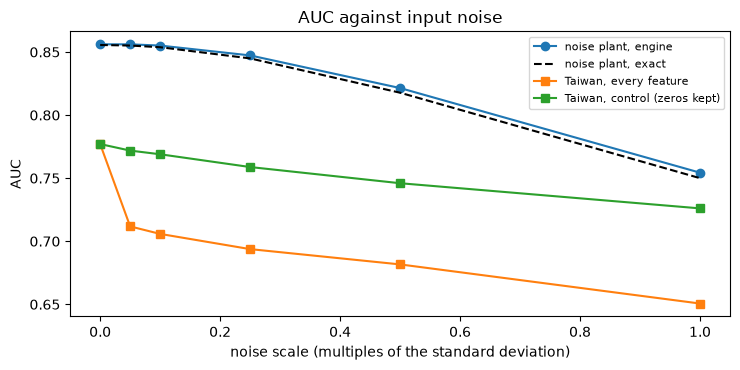

In [6]:
# Mean AUC against the noise scale: the noise plant (engine and exact) and the committed Taiwan model
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(curve.grid, curve.auc, "o-", label="noise plant, engine")
ax.plot(truth["grid"], truth["auc"], "k--", label="noise plant, exact")
for segment, committed in committed_curves.items():
    name = "Taiwan, control (zeros kept)" if segment.startswith("control") else "Taiwan, every feature"
    ax.plot(committed.grid, committed.auc, "s-", label=name)
ax.set_xlabel("noise scale (multiples of the standard deviation)")
ax.set_ylabel("AUC")
ax.set_title("AUC against input noise")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The engine's curve on the noise plant lies on top of the exact one, so the noise machinery adds nothing of its own to
the loss. The Taiwan model with Gaussian noise on every feature drops far faster than the plant (a loss of 0.0712 at a
scale of 0.1), and the control curve, which keeps every exact zero at zero, loses only 0.0081 there. The gap between the two Taiwan curves
is the payment-status codes, not the model: the figure shows that a robustness light depends on how the noise is
defined as much as on the model it is applied to.

### Step 3: resilience, the worst subsample by a shift score

Robustness perturbs the inputs the model sees. Resilience asks how the model does where the evaluation sample is **unlike development**. Two steps, both in the engine:

1. **The shift score.** A ridge logistic classifier tells development rows (class 0) from evaluation rows (class 1); each evaluation row gets the probability of belonging to evaluation, $r_i \in [0,1]$, from a fold that did not train on it. Two samples that agree score 0.5 on average.
2. **The worst subsample.** The $\lceil q\,n\rceil$ evaluation rows with the highest $r_i$ (the dossier's example is $q = 0.1$) are scored with the same model: $\Delta = \mathrm{AUC}_{\text{all}} - \mathrm{AUC}_{\text{worst}}$. A subsample with a single class has no AUC and the engine raises.

On the shift plant a quarter of the evaluation rows have the first covariate shifted by 2 standard deviations, into a region where the true relation reverses its slope. The model is the linear fit valid inside development. The development set must hold at least twice the evaluation rows for the reference of the next step, so the next cell draws 3,000 rows and keeps the first 1,000 of the evaluation sample.

In [7]:
# Draw the shift plant and the null plant (no shift), score the evaluation rows, take the worst 25 percent
SHARE = 0.25
cases = {}
for label, shift in (("shifted", 2.0), ("no shift", 0.0)):
    plant = plants.CovariateShiftPlant(n=3000, shift=shift, features=[0], seed=3)
    d = plant.sample()
    x_dev, y_dev = d["X_dev"], d["y_dev"]
    x_eval, y_eval, moved = d["X_eval"][:1000], d["y_eval"][:1000], d["shifted"][:1000]
    score = rob.shift_score_rank(x_dev, x_eval, seed=1)
    worst = rob.worst_subsample_performance(plant.predict, x_eval, y_eval, score, SHARE)
    top = np.argsort(-score, kind="stable")[: worst.n]
    cases[label] = (plant, x_dev, y_dev, x_eval, y_eval, score, worst)
    print(f"{label:18s} rows moved by the plant {moved.mean():.3f}")
    print(f"{'':18s} moved rows inside the worst subsample {moved[top].mean():.3f}")
    print(f"{'':18s} AUC all rows {worst.auc_full:.4f} | AUC worst {worst.n} rows {worst.auc:.4f}", end=" ")
    print(f"| raw drop {worst.auc_full - worst.auc:.4f}")

shifted            rows moved by the plant 0.242
                   moved rows inside the worst subsample 0.748
                   AUC all rows 0.8842 | AUC worst 250 rows 0.7075 | raw drop 0.1767
no shift           rows moved by the plant 0.000
                   moved rows inside the worst subsample 0.000
                   AUC all rows 0.8965 | AUC worst 250 rows 0.8913 | raw drop 0.0052


Two things stand out. The score does find the shifted rows: nearly all of the worst subsample is rows the plant moved. And **the raw drop is not zero where nothing moved**: on the no-shift plant the worst quarter by shift score is a region of the feature space, and the AUC on a restricted range is lower than on the whole sample. A rule such as "red if the drop exceeds a fixed number" would therefore fire on a stable model. The engine reads the drop against a reference built from the development rows alone.

### Step 4: the permutation reference

The reference answers the question "how big a drop does a random group of rows of this size and kind show when there is no shift?". From the development rows alone, $R$ times (the engine's default is $R = 199$, a convention) it:

1. draws a random subset of the development rows of the evaluation size as a pseudo-evaluation set, the other development rows being the pseudo-development set;
2. refits the shift score on that split, exactly as in step 3;
3. computes the drop $\Delta^{(b)}$ on the pseudo-evaluation rows with the same worst-subsample rule.

The one-sided permutation p-value counts how often the null drops reach the observed one, with the observed value counted in (Phipson and Smyth, 2010: a permutation p-value is never zero):

$$p = \frac{1 + \#\{b : \Delta^{(b)} \ge \Delta_{\text{obs}}\}}{R + 1}.$$

Under no shift the evaluation rows are exchangeable with the development rows, so the null is valid and holds no shifted row, and the range-restriction effect of step 3 is in the null as well. A draw whose worst subsample has a single class has no AUC and is left out (`n_undefined`). The light reads the p-value: red below 0.01, amber below 0.05. The next cell builds the reference for both plants and calls the engine test.

In [8]:
# Build the development-only reference with 199 permutations for each plant and call the engine test
resilience = {}
for label, (plant, x_dev, y_dev, x_eval, y_eval, score, worst) in cases.items():
    reference = rob.shift_development_reference(
        plant.predict, x_dev, y_dev, x_eval, y_eval, score, SHARE, shift_permutations=199, seed=2
    )
    result = vml.shift_resilience("shift-plant", worst, reference)
    resilience[label] = (reference, result)
    ex = result.extras
    print(
        f"{label:18s} observed drop {reference.observed_drop:.4f} | null mean {ex['null_mean']:.4f}", end=" "
    )
    print(f"| null 95th percentile {ex['null_p95']:.4f}")
    print(f"{'':18s} p = {result.p_value:.4f} | light {LIGHT[result.light.value]}", end=" ")
    print(f"| draws left out {reference.n_undefined}")

shifted            observed drop 0.1767 | null mean 0.0161 | null 95th percentile 0.0820
                   p = 0.0100 | light amber | draws left out 0
no shift           observed drop 0.0052 | null mean 0.0161 | null 95th percentile 0.0820
                   p = 0.5950 | light green | draws left out 0


A p-value from 199 draws is a position in a histogram. The next cell draws, for each plant, the null drops built from
the development rows alone and marks the drop observed on the worst quarter of the evaluation rows.

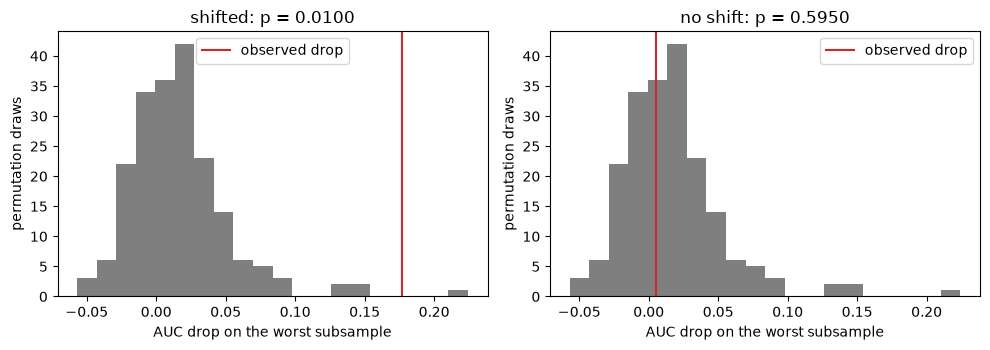

In [9]:
# Null drops of the permutation reference against the observed drop, for both plants
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True)
for ax, (label, (reference, result)) in zip(axes, resilience.items()):
    ax.hist(reference.null_drops, bins=20, color="tab:gray")
    ax.axvline(reference.observed_drop, color="tab:red", label="observed drop")
    ax.set_title(f"{label}: p = {result.p_value:.4f}")
    ax.set_xlabel("AUC drop on the worst subsample")
    ax.set_ylabel("permutation draws")
    ax.legend()
fig.tight_layout()
plt.show()

The grey histogram is what a random group of rows of this size shows when nothing moved, and it is not centred on zero:
its mean is 0.0161 and its 95th percentile 0.0820, because any worst quarter by a shift score is a restricted region.
On the shifted plant the observed drop of 0.1767 lies beyond almost every null draw (p = 0.0100), while on the no-shift
plant the drop of 0.0052 sits inside the bulk (p = 0.5950). Because the null alone reaches 0.0820 at its 95th
percentile, a fixed cut such as 0.05 would fire on many stable models, which is why the engine reads the drop against
this reference.

### Step 5: out-of-time windows

The second resilience reading is the AUC of each out-of-time window, with a window left out when it holds a single class (it never gets a number). The plants have no calendar, so two groupings stand in for windows: four blocks of consecutive evaluation rows (rows are in random order, so the blocks should agree), and the plant's own flag of shifted against unshifted rows. The engine function takes any integer window label.

In [10]:
# AUC per window for four blocks of rows and for the plant's shifted flag
plant, x_dev, y_dev, x_eval, y_eval, score, worst = cases["shifted"]
shifted_plant = plants.CovariateShiftPlant(n=3000, shift=2.0, features=[0], seed=3)
moved_flag = shifted_plant.sample()["shifted"][:1000].astype(int)
blocks = np.repeat(np.arange(4), 250)
for label, window in (("four blocks of rows", blocks), ("unshifted (0) against shifted (1)", moved_flag)):
    by_window = rob.oot_window_performance(plant.predict, x_eval, y_eval, window)
    shown = {("omitted" if k == "omitted" else k): round(v, 4) for k, v in by_window.items()}
    print(label + ":", shown)

four blocks of rows: {'0': 0.903, '1': 0.8832, '2': 0.8663, '3': 0.8862, 'omitted': 0.0}
unshifted (0) against shifted (1): {'0': 0.8893, '1': 0.7871, 'omitted': 0.0}


### Step 6: the overfit gap

The overfit test compares the metric on the training slice with the metric on the holdout:

$$\text{gap} = \mathrm{AUC}_{\text{train}} - \mathrm{AUC}_{\text{holdout}} \quad (\text{for the Brier score the sign is reversed}),\qquad \text{flag if gap} > 0.05 .$$

The tolerance 0.05 is a named convention. The gap is rounded to 12 decimals before it is compared, so a gap that is exactly the tolerance in decimals is not flagged: $0.80 - 0.75$ is $0.050000000000000044$ in floats. The light is red above the tolerance and green otherwise, never amber. The engine takes the two metrics as numbers, so the next cell shows the rule on pairs written in the cell, including the boundary.

In [11]:
# The overfit rule on pairs written in the cell: below, at and above the tolerance, and the Brier direction
for train, holdout in ((0.78, 0.76), (0.80, 0.75), (0.80, 0.74)):
    r = gen.overfit_gap(train, holdout, tolerance=0.05)
    light = vml.overfit("demo", r).light.value
    print(f"AUC {train:.2f} / {holdout:.2f} | raw {train - holdout!r} | gap used {r.gap!r}", end=" ")
    print(f"| flag {YN[bool(r.flag)]} | light {LIGHT[light]}")
brier = gen.overfit_gap(0.10, 0.17, tolerance=0.05, higher_is_better=False)
print("Brier 0.10 / 0.17 | gap", brier.gap, "| flag", YN[bool(brier.flag)])

AUC 0.78 / 0.76 | raw 0.020000000000000018 | gap used 0.02 | flag no | light green
AUC 0.80 / 0.75 | raw 0.050000000000000044 | gap used 0.05 | flag no | light green
AUC 0.80 / 0.74 | raw 0.06000000000000005 | gap used 0.06 | flag yes | light red
Brier 0.10 / 0.17 | gap 0.07 | flag yes


### Step 7: weak spots

A model can be good on average and poor in a corner. The weak-spot test slices the data by a feature (here the deciles of the first covariate), takes the per-row loss (the Brier term $(p_i - y_i)^2$) and reports every slice with at least $n_{\min} = 30$ rows whose mean loss exceeds $k = 2$ times the overall mean:

$$\text{ratio}_s = \frac{\bar{e}_s}{\bar{e}}, \qquad \text{weak spot if } \text{ratio}_s > k .$$

The light is amber when the worst ratio exceeds $k$ and green otherwise; it is never red. The noise plant has a second column of pure noise, so a model that uses only the signal column is equally good in every slice of it. The next cell first runs the test on that honest model, then **plants a defect**: in one decile of the noise column the model's probability is replaced by its complement (the model is upside down there). A validator plants a defect to see whether the test finds it.

In [12]:
# Slice the noise-plant rows by decile of the noise column: the honest model, then one upside-down slice
probability = noise_plant.predict(draw["X"])
edges = np.quantile(draw["X"][:, 1], np.linspace(0, 1, 11)[1:-1])
slice_label = np.digitize(draw["X"][:, 1], edges)
PLANTED_SLICE = 6
damaged = np.where(slice_label == PLANTED_SLICE, 1.0 - probability, probability)
models = (("honest model", probability), ("model with slice 6 upside down", damaged))
for label, p in models:
    error = (p - draw["y"]) ** 2
    spots = gen.weak_spots(error, slice_label, k=2.0, min_n=30)
    result = vml.weak_spot("noise-plant", spots, 2.0, len(np.unique(slice_label)))
    print(f"{label:34s} overall mean error {error.mean():.4f} | weak spots {len(spots)}", end=" ")
    print(f"| light {LIGHT[result.light.value]} | worst ratio {result.metric:.3f}")
    for sp in spots:
        print(f"    slice {sp.label} | n {sp.n} | mean error {sp.mean_error:.4f} | ratio {sp.ratio:.3f}")

honest model                       overall mean error 0.1591 | weak spots 0 | light green | worst ratio 0.000
model with slice 6 upside down     overall mean error 0.1901 | weak spots 1 | light amber | worst ratio 2.448
    slice 6 | n 2000 | mean error 0.4655 | ratio 2.448


The table above lists one slice, and the shape of the damage is easier to see on all ten at once. The next cell draws
the mean error of each decile for the honest model and for the one with slice 6 turned upside down, against the
threshold of twice the overall mean error.

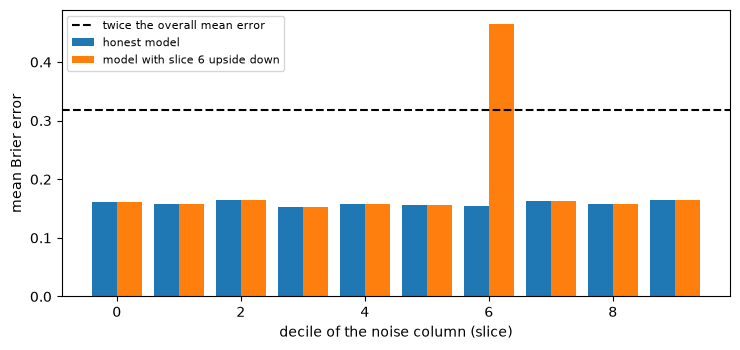

In [13]:
# Mean error by decile of the noise column: the honest model and the model with one slice upside down
fig, ax = plt.subplots(figsize=(7.5, 3.6))
slices = np.arange(10)
for offset, (label, p) in zip((-0.2, 0.2), models):
    error = (p - draw["y"]) ** 2
    by_slice = [error[slice_label == s].mean() for s in slices]
    ax.bar(slices + offset, by_slice, width=0.4, label=label)
overall = ((probability - draw["y"]) ** 2).mean()
ax.axhline(2 * overall, color="black", linestyle="--", label="twice the overall mean error")
ax.set_xlabel("decile of the noise column (slice)")
ax.set_ylabel("mean Brier error")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The honest model has the same error in every decile, all of them far below the dashed line. The damaged model differs
in a single decile, slice 6, whose mean error of 0.4655 is the only bar above the threshold; the other nine are
unchanged. A global metric blurs this: the overall error only rises from 0.1591 to 0.1901, while the slice view shows
exactly where the model is wrong and by how much, which is what the weak-spot test reports.

### Step 8: the committed rows of case C20

The pipeline ran these tests on real models and wrote one row each. The next cell lists the overfit and weak-spot rows of the three documents with their gap, ratio and light, and the shift-resilience row of the Federal Reserve shift with the permutation reference it used. The engine that baked them is the version printed in the Data section.

In [14]:
# List the committed overfit, weak-spot and shift-resilience rows with their values and lights
wanted = ("ml.overfit", "ml.weak_spot", "ml.shift_resilience")
for label, doc in (("perturbation-grid", perturbation), ("fed-shift", fed), ("seed-sweep", seeds)):
    for t in doc["tests"]:
        if t["test_id"] not in wanted:
            continue
        extra = ""
        if t["test_id"] == "ml.weak_spot":
            extra = f" | slices {t['n']} weak spots {t['extras']['n_spots']}"
        if t["test_id"] == "ml.shift_resilience":
            x = t["extras"]
            extra = (
                f" | p {t['p_value']:.4f} null mean {x['null_mean']:.4f} draws {x['shift_permutations']}"
                f" AUC all/worst {x['auc_full']:.4f}/{x['auc_worst']:.4f}"
            )
        head = f"{label:18s} {t['test_id']:20s} {t['model_id'][:22]:22s}"
        print(head, f"value {t['metric']:.4f} light {LIGHT[t['light']]}{extra}")

perturbation-grid  ml.overfit           P4-lightgbm-taiwan     value 0.0297 light green
perturbation-grid  ml.weak_spot         P4-lightgbm-taiwan     value 0.0000 light green | slices 11 weak spots 0
fed-shift          ml.shift_resilience  P4-lightgbm-polish     value 0.0857 light red | p 0.0050 null mean 0.0007 draws 199 AUC all/worst 0.6914/0.6056
fed-shift          ml.overfit           P4-lightgbm-polish     value 0.0843 light red
seed-sweep         ml.overfit           P4-lightgbm-taiwan     value 0.0297 light green
seed-sweep         ml.overfit           P4-xgboost-taiwan      value 0.0242 light green


## Results

**Answer:** Not unconditionally: the model holds under mild noise and fails where the tests are built to look. On the noise plant the AUC loss is 0.0088 at a noise scale of 0.25 (green) and 0.1018 at 1.00 (red); the committed Taiwan model loses 0.0712 at a scale of 0.1 when noise goes on every feature, against 0.0081 when exact zeros are kept. On a shifted evaluation sample the AUC falls from 0.8842 to 0.7075 on the worst quarter (permutation p = 0.0100), and the committed Polish model overfits by a gap of 0.0843 (red).

- **The engine's noise curve is the exact curve.** On the noise plant the measured AUC follows the closed form at every scale (the largest gap printed is under 0.005, the sampling error of 20,000 rows), and the finding follows the tolerance: at a pre-set scale of 0.25 the loss is 0.0088 and the light is green, at 1.00 it is 0.1018, a finding, and red.
- **The committed Taiwan model fails the noise test, and the control curve says why.** Adding noise to every feature costs 0.0712 of AUC at a scale of 0.1 (red); the control curve that keeps every exact zero at zero costs 0.0081 (green). Rebuilt from the committed values and passed through the engine's test, both rows give the committed loss and light. The gap between the two curves is the payment-status codes: a Gaussian added to a code is not a measurement error, so the red light measures the choice of noise as much as the model. A validator should read the two curves together.
- **The shift score finds the shifted rows, and the raw drop needs its reference.** On the shifted plant 74.8% of the worst quarter by shift score are rows the plant moved (24.2% of the sample), and the AUC falls from 0.8842 to 0.7075, a drop of 0.1767. Where nothing moved the drop is small (0.0052), but the development-only reference shows what chance does: the null drops average 0.0161 and their 95th percentile is 0.0820, because the worst quarter by a shift score is a region of the feature space and the AUC on a restricted range is lower. The permutation p-value is 0.0100 (amber) on the shifted plant and 0.5950 (green) on the no-shift plant. The smallest p-value that 199 draws can give is 0.005.
- **Out-of-time windows agree with the plant.** Four blocks of rows give AUC between 0.8663 and 0.9030; the shifted rows give 0.7871 against 0.8893 for the unshifted ones.
- **The overfit rule is exact at the boundary.** The pair 0.80 and 0.75 has a floating-point gap of 0.050000000000000044 and a rounded gap of 0.05, which is not above the tolerance: green. 0.80 and 0.74 is flagged and red. For the Brier score the direction reverses, and a rise of 0.07 is a gap of 0.07.
- **The weak-spot test finds only what is there.** The honest model has no slice above twice the average error (green). With one decile of the noise column turned upside down, the overall error rises from 0.1591 to 0.1901 and the test reports that slice with a ratio of 2.448 (amber), which a global metric would blur.
- **The committed rows are the same tests on real models.** The Taiwan LightGBM gap is 0.0297 (green) and its eleven slices of the PAY_0 payment-status column hold no weak spot; the XGBoost refit has 0.0242 (green). The Polish LightGBM model has a gap of 0.0843 (red). On the Federal Reserve shift at the full anchor the worst tenth has an AUC of 0.6056 against 0.6914 for all rows, a drop of 0.0857 with p = 0.0050 over 199 draws and a null mean of 0.0007: red. All the rows were baked with riskvalidation 1.0.1.

What the results do not show: the plants have no calendar, so the windows are stand-ins; the shift in the Federal Reserve document is synthetic and sized by the PSI of a rating, not an observed change in the Polish companies; the tolerances (0.02, 0.05, 2), the share of the worst subsample and the 199 draws are conventions; and a green light is the absence of these particular findings.

## Summary

- Robustness adds noise of scale $\varepsilon$ to the evaluation features only, with the same draws at every scale, and raises a finding when the AUC loss at a pre-set scale exceeds the tolerance; the engine's curve matches the plant's exact curve.
- Resilience scores the model on the evaluation rows that resemble development least; the raw AUC drop is positive even without shift, so the engine reads it against an exact permutation reference built from the development rows (199 draws, p = (1 + count) / (R + 1)).
- Overfit is the train minus holdout gap against 0.05, exact at the boundary; weak spots are the slices whose error is more than twice the average, with at least 30 rows.
- The committed C20 rows are the same tests on real models, all baked with riskvalidation 1.0.1: the Taiwan model fails the noise test only when noise is added to status codes, the Polish model overfits, and the synthetic Federal Reserve shift is found.
- Every tolerance is a named convention, and a green light is the absence of a finding.

**What to try next.** Notebook 03 asks whether the explanations of the same model stay put when the training seed changes. Notebook 13-09 measures how often the resilience test fires on a model that has not changed, and how often it finds one that has.

## References

- PiML-Toolbox (Apache-2.0), outcome tests WeakSpot, Overfit, Reliability, Robustness and Resilience; Sudjianto et al. (2023), arXiv 2305.04214. https://github.com/SelfExplainML/PiML-Toolbox
- ECB (2025), Guide to internal models, the paragraphs on the randomness of the training process, overfitting, explainability and the justification of complexity (43, 59, 60, 62, 64 to 66). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.supervisory_guide202507.en.pdf
- Phipson, B. and Smyth, G. K. (2010), Permutation p-values should never be zero, Statistical Applications in Genetics and Molecular Biology 9(1). https://doi.org/10.2202/1544-6115.1585
- Yeh, I-C. and Lien, C-H., Default of credit card clients, UCI Machine Learning Repository (CC BY 4.0), the Taiwan cards of the C20 variants. https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
- Board of Governors of the Federal Reserve System, supervisory stress test scenarios and methodology data (public domain), the three corporate portfolios of 2025. https://www.federalreserve.gov/supervisionreg/dfa-stress-tests-2026.htm